
# Exploring M87 Galaxy using Python and different Astronomical Surveys

---



## In this session
* Understand about the M87 Galaxy
* Understand about the powerful jets it has
* Explore the M87 Galaxies using Optical and Radio Surveys
* Extract the features by implementing sato filter / other filter of your choice

---


### Quick intro to Messier 87 (M87) Galaxy
* Messier 87 (also known as Virgo A or NGC 4486, generally abbreviated to M87) is a supergiant elliptical galaxy in the constellation Virgo that contains several trillion stars.

* One of the largest and most massive galaxies in the local universe, it has a large population of globular clusters—about 15,000 compared with the 150–200 orbiting the Milky Way.

* It also has a jet of energetic plasma that originates at the core and extends at least 1,500 parsecs (4,900 light-years), traveling at a relativistic speed.

* It is one of the brightest radio sources in the sky and a popular target for both amateur and professional astronomers.

### First-ever Image of a Black Hole - Powehi (M87*)

<img src='https://i.natgeofe.com/n/96ea8fe8-5dc7-4b00-ade3-653d84513dbd/01-black-hole-a-consensus.jpg?w=1280&h=746' width = 50%>

### Magnetic Fields at the Edge of Powehi

<img src = 'https://www.eaobservatory.org/jcmt/wp-content/uploads/sites/2/2021/03/CompositePolPressRelease_v1c.jpg' width = 50%>

### The galactic core of M87

* The blue plasma jet clearly visible (composite image of observations by the Hubble Space Telescope in visible and infrared light)

<img src='https://upload.wikimedia.org/wikipedia/commons/thumb/0/07/Messier_87_Hubble_WikiSky.jpg/435px-Messier_87_Hubble_WikiSky.jpg' width=50%>

### Superluminal Motion

* Check this [wiki article](https://en.wikipedia.org/wiki/Superluminal_motion#:~:text=Superluminal%20motion%20of%20up%20to%206c%20has%20been%20observed%20in,Earth's%20line%2Dof%2Dsight.)

### One processed image from Radio Survey - VLA

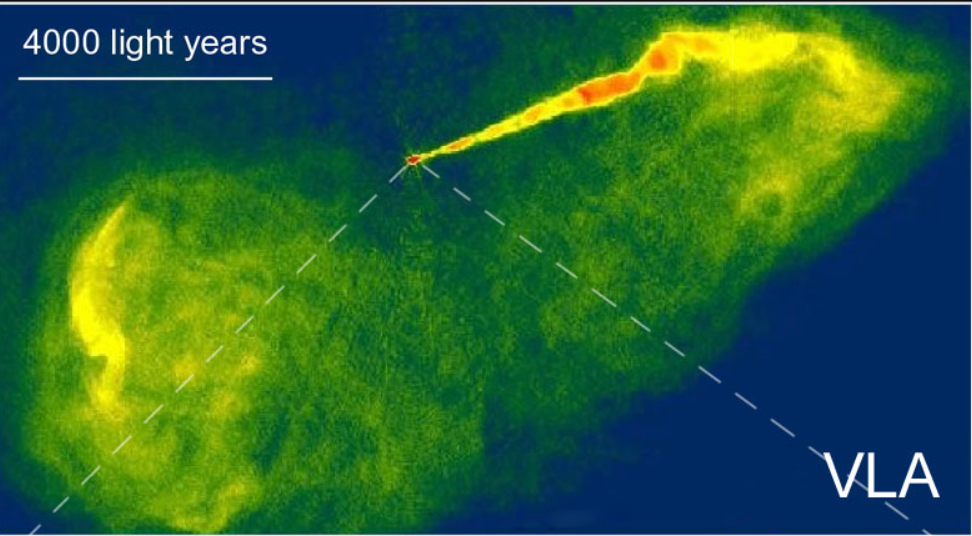

### Let's begin with exploring M87 using Python

In [ ]:
# Install astroquery package
!pip install astroquery

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.3/5.3 MB 18.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 910.8/910.8 kB 27.7 MB/s eta 0:00:00


In [ ]:
# Import numpy library
import numpy as np

# Import pyplot from matplotlib
import matplotlib.pyplot as plt

In [ ]:
# Import SkyView from astroquery (present in skyview)
from astroquery.skyview import SkyView

# Import WCS from astropy (present in wcs)
from astropy.wcs import WCS

from astropy.io import fits

In [ ]:
# Ignore warning messages
import warnings
warnings.filterwarnings('ignore')

In [ ]:
# SkyView.list_surveys()

In [ ]:
# Query for SDSS g images centered on the target name M87 and get the primary hdu
hdu = SkyView.get_images(position="M87", survey="SDSSg")
# hdu = hdu[0][0]
# fitsfile = SkyView.get_image_list(position="M87", survey=['SDSSg'], cache=False)


In [ ]:
# fitsfile[0]

'https://skyview.gsfc.nasa.gov/tempspace/fits/skv4486701119656.fits'

In [ ]:
# hdu = fits.open(fitsfile[0])

In [ ]:
# Query for VLA image - Radio
vla_hdu = SkyView.get_images(position="M87", survey="VLA FIRST (1.4 GHz)")
vla_hdu = vla_hdu[0][0]

In [ ]:
print(hdu)
print(vla_hdu)

In [ ]:
WCS(hdu.header)

WCS Keywords

Number of WCS axes: 2
CTYPE : 'RA---TAN'  'DEC--TAN'  
CRVAL : 187.706  12.3911  
CRPIX : 150.5  150.5  
PC1_1 PC1_2  : 1.0  0.0  
PC2_1 PC2_2  : 0.0  1.0  
CDELT : -0.00011  0.00011  
NAXIS : 300  300

In [ ]:
WCS(vla_hdu.header)

WCS Keywords

Number of WCS axes: 2
CTYPE : 'RA---TAN'  'DEC--TAN'  
CRVAL : 187.706  12.3911  
CRPIX : 150.5  150.5  
PC1_1 PC1_2  : 1.0  0.0  
PC2_1 PC2_2  : 0.0  1.0  
CDELT : -0.0005  0.0005  
NAXIS : 300  300

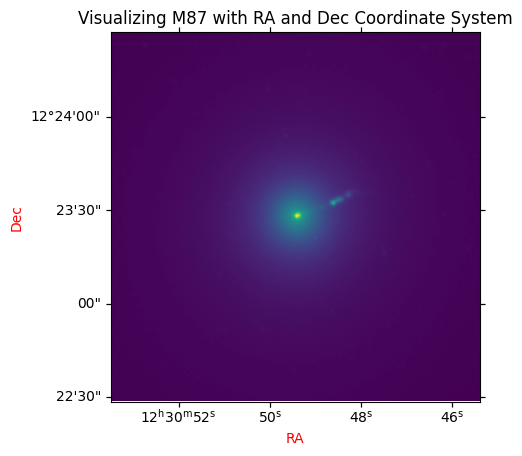

In [ ]:
# Tell matplotlib how to plot WCS axes
wcs =   WCS(hdu.header)             # Where in hdu the wcs info is present
ax =    plt.subplot(projection=wcs) # use wcs as the axes projection

# Display the image with appropriate x label and y labe along with title of the plot
plt.imshow(hdu.data, origin='lower')
plt.xlabel('RA', color = 'r')
plt.ylabel('Dec', color = 'r')
plt.title('Visualizing M87 with RA and Dec Coordinate System')
plt.show()

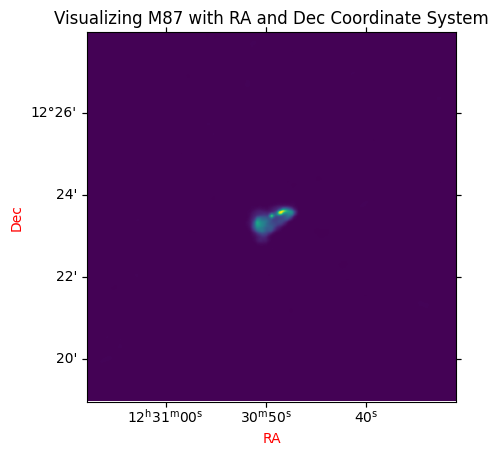

In [ ]:
''' Repeat this for VLA '''
# Tell matplotlib how to plot WCS axes
wcs = WCS(vla_hdu.header)                 # Where in hdu the wcs info is present
ax = plt.subplot(projection=wcs)      # use wcs as the axes projection

# Display the image with appropriate x label and y labe along with title of the plot
plt.imshow(vla_hdu.data, origin='lower')
plt.xlabel('RA', color = 'r')
plt.ylabel('Dec', color = 'r')
plt.title('Visualizing M87 with RA and Dec Coordinate System')
plt.show()

* We will continue with Optical Image in this notebook
* You can later on try any image processing on Radio Image later on

In [ ]:
# Create a variable called M87 that stores the primary hdu that we querried in above code cell
M87 = hdu

In [ ]:
# Create a variable called M87_Pixels to store the image data from the primary hdu of M87
M87_Pixels = hdu.data

In [ ]:
# Check the shape of M87_Pixels
M87_Pixels.shape

(300, 300)

#### Log Normalization

In [ ]:
# Define a function for log normalization
def log_norm(img):
  return np.log(img)

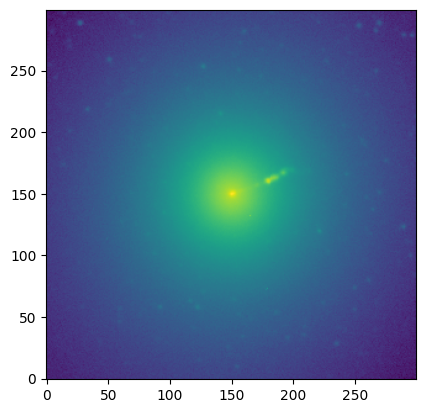

In [ ]:
# Display the image with log normalization implemented on it
plt.imshow(log_norm(M87_Pixels), origin='lower')
plt.show()

#### ZScaleInterval

In [ ]:
from astropy.visualization import ZScaleInterval

In [ ]:
# Create an object called z of class ZScaleInterval
z = ZScaleInterval(contrast=0.1)

In [ ]:
# What is the meaning of z1 and z2 here?
z1,z2 = z.get_limits(M87_Pixels)

In [ ]:
# Print z1 and z2 values here
print(z1)
print(z2)

0.20751953
6.584756291537055


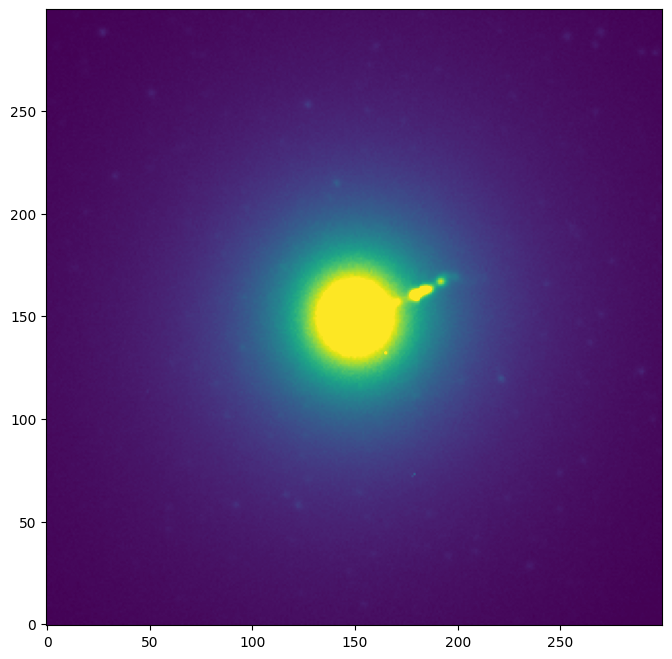

In [ ]:
fig = plt.figure(figsize=(8,8))
img = plt.imshow(M87_Pixels,vmin=z1,vmax=z2, origin='lower')

In [ ]:
M87_Pixels.shape

(300, 300)

In [ ]:
# RGBA image of img used in above cell
arr = img.make_image(renderer=None, unsampled=True)[0]

In [ ]:
arr

array([[[ 68,   2,  85, 255],
        [ 68,   3,  87, 255],
        [ 68,   3,  87, 255],
        ...,
        [ 68,   1,  84, 255],
        [ 68,   1,  84, 255],
        [ 68,   1,  84, 255]],

       [[ 68,   3,  87, 255],
        [ 68,   3,  87, 255],
        [ 68,   3,  87, 255],
        ...,
        [ 68,   1,  84, 255],
        [ 68,   2,  85, 255],
        [ 68,   3,  87, 255]],

       [[ 68,   2,  85, 255],
        [ 68,   3,  87, 255],
        [ 69,   6,  90, 255],
        ...,
        [ 68,   1,  84, 255],
        [ 68,   1,  84, 255],
        [ 68,   2,  85, 255]],

       ...,

       [[ 68,   1,  84, 255],
        [ 68,   1,  84, 255],
        [ 68,   1,  84, 255],
        ...,
        [ 68,   3,  87, 255],
        [ 69,   5,  88, 255],
        [ 68,   3,  87, 255]],

       [[ 68,   1,  84, 255],
        [ 68,   1,  84, 255],
        [ 68,   1,  84, 255],
        ...,
        [ 69,   5,  88, 255],
        [ 68,   3,  87, 255],
        [ 68,   1,  84, 255]],

       [[ 68

In [ ]:
# Check the shape of arr
arr.shape

(300, 300, 4)

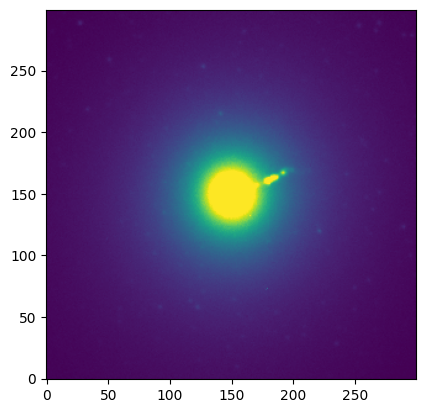

In [ ]:
# Display the arr
plt.imshow(arr, origin='lower')

In [ ]:
# Check the 4th channel on index 3 of arr
np.unique(arr[:,:,3])

array([255], dtype=uint8)

In [ ]:
# Chage these pixels to some other value (in between 0 - 255)
arr[:,:,3] = 255

In [ ]:
np.unique(arr[:,:,3])

array([255], dtype=uint8)

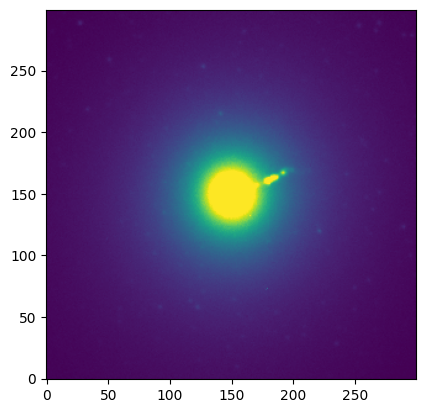

In [ ]:
# Display arr again
plt.imshow(arr, origin='lower')

In [ ]:
import cv2

In [ ]:
image = cv2.imread('img', 1)
# image

In [ ]:
# Use cvtColor of cv2 to convert from BGRA2RGB
img = cv2.cvtColor(arr, cv2.COLOR_BGRA2RGB)
# complete this code

In [ ]:
# Check the shape of the img
img.shape

(300, 300, 3)

In [ ]:
# Change from BGR2GRAY using same format as used in 2 cells above and save it as grayscale variable
grayscale = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

In [ ]:
# Check the shape of grayscale
grayscale.shape

(300, 300)

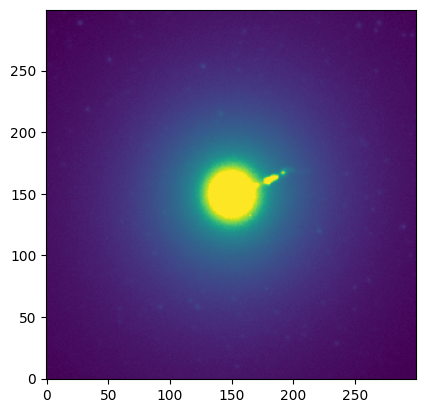

In [ ]:
# Display the grayscale output
plt.imshow(grayscale, origin='lower')

Apply Filters

In [ ]:
# Use spectral_list as colormap for visualisation
SPECTRAL_LIST = ["gray","jet","hot","prism","nipy_spectral",
             "gist_ncar","gist_earth","gist_stern","flag","gnuplot2","afmhot",
            "bwr",'PiYG','PRGn','BrBG','PuOr','RdGy','RdBu','terrain']

In [ ]:
# Import Sato filter from skimage
from skimage.filters import sato

In [ ]:
# Apply sato filter on grayscale and store it as M_87_sato
M_87_sato = sato(grayscale)
M_87_Pixels_sato = sato(M87_Pixels)

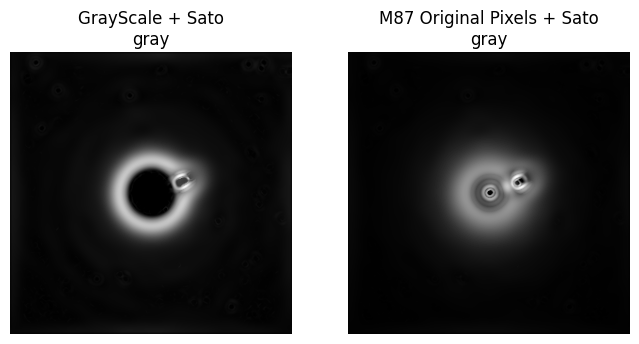

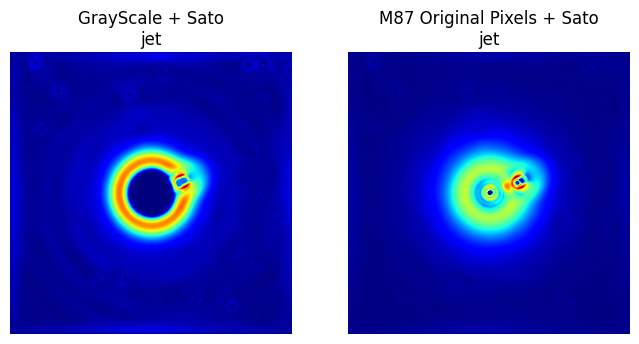

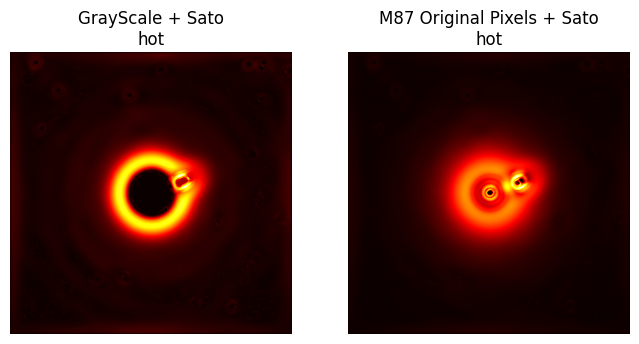

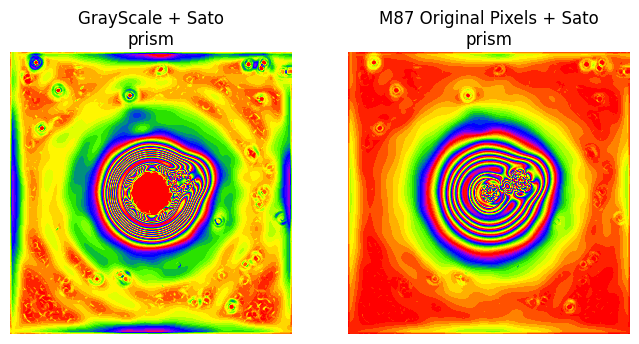

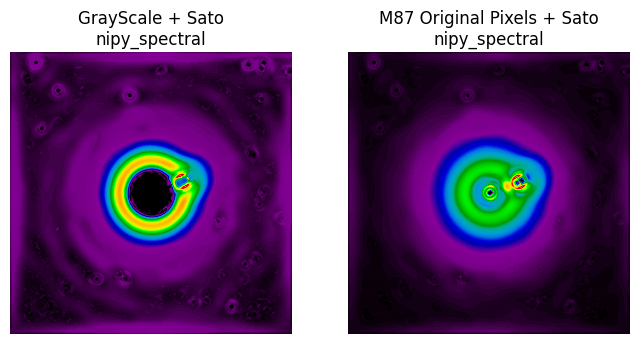

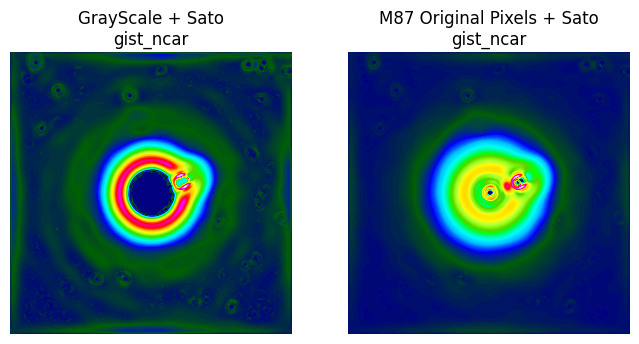

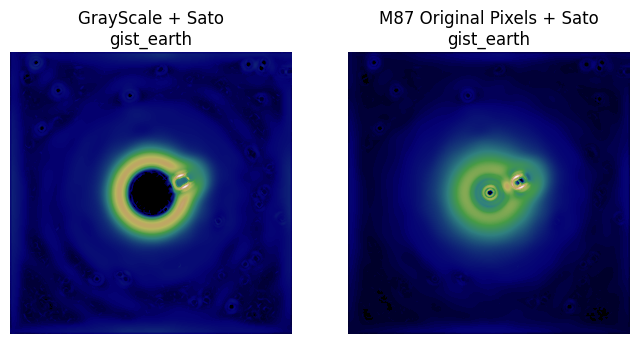

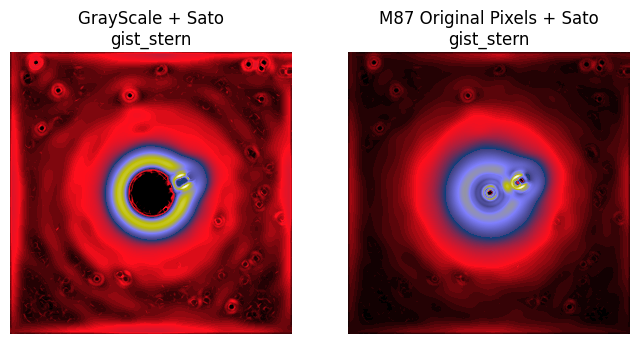

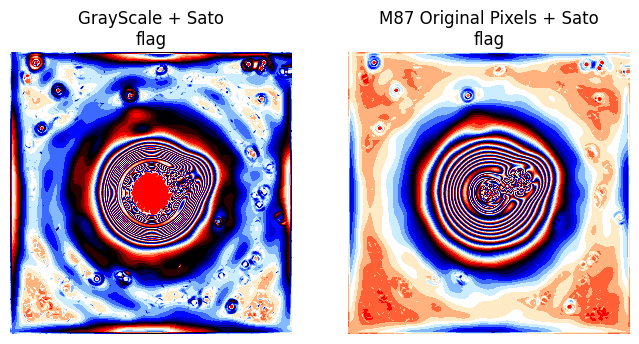

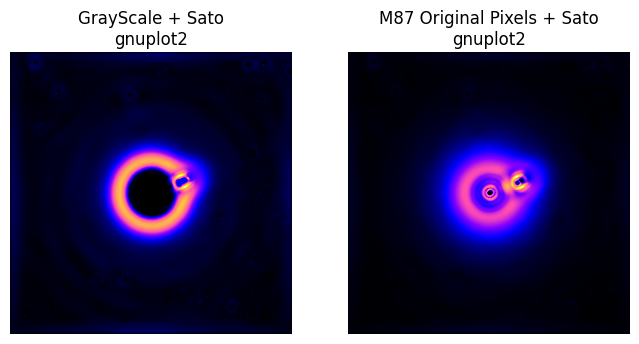

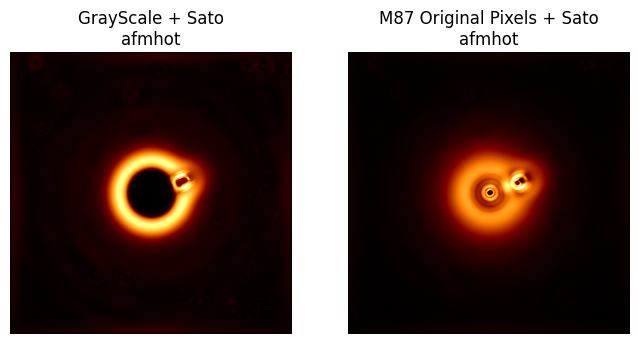

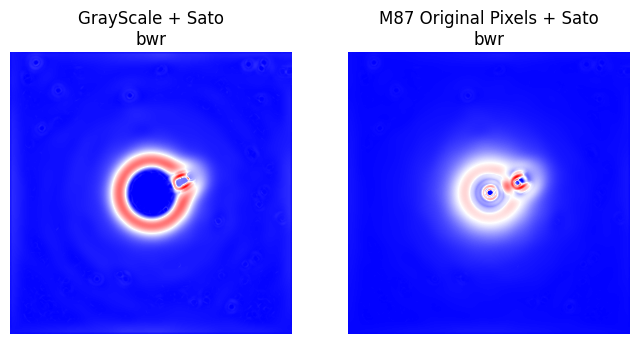

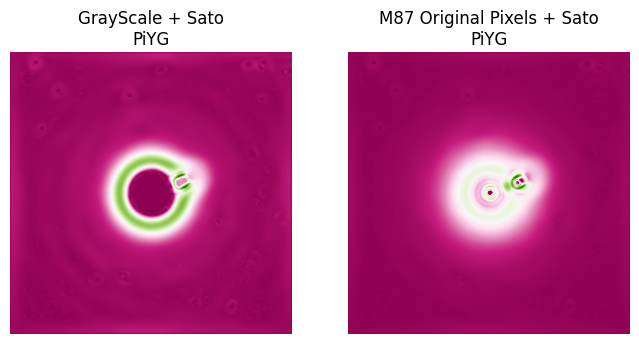

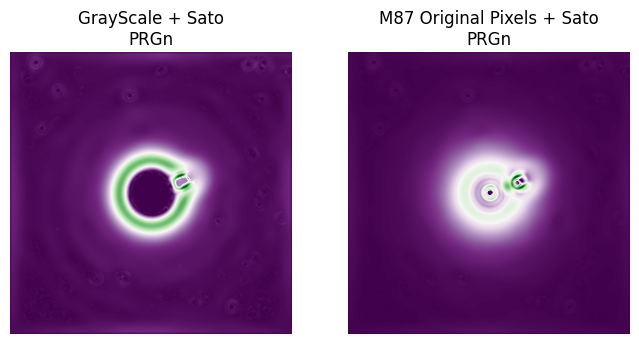

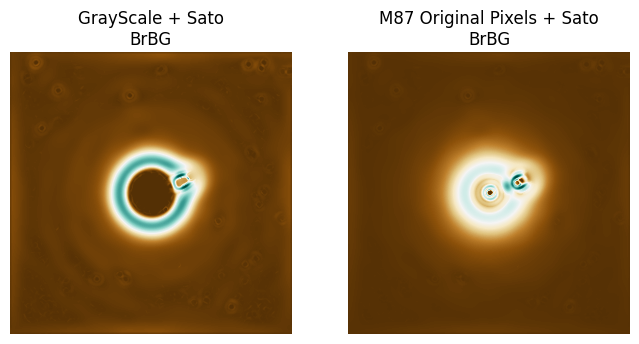

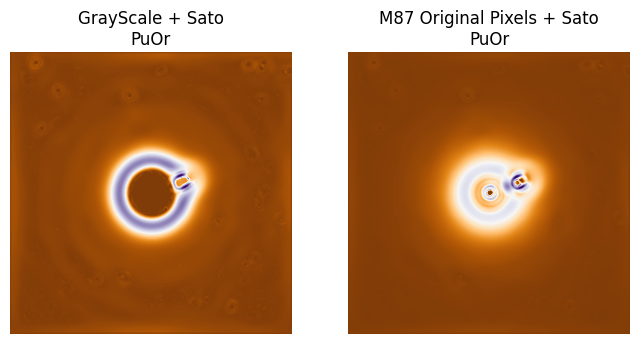

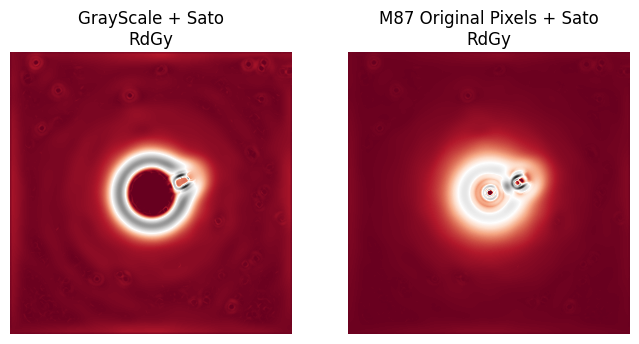

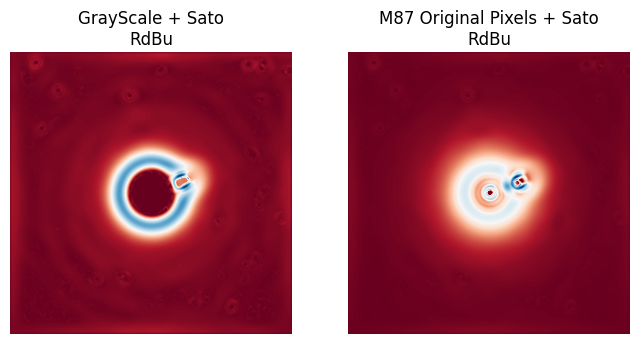

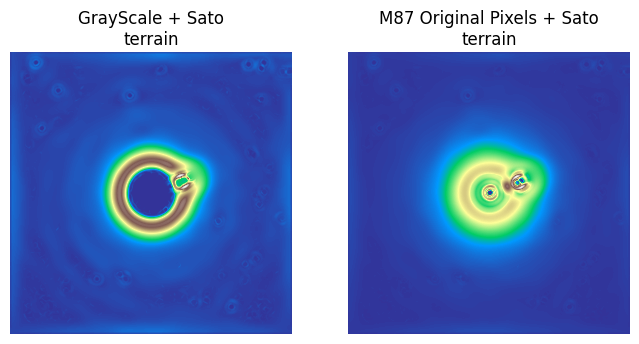

<Figure size 640x480 with 0 Axes>

In [ ]:
# Write a for loop with all the colormap given in list above to visualize the output of M_87_sato
for cmap in SPECTRAL_LIST:
  plt.figure(figsize=(8,8))
  plt.subplot(121)
  plt.imshow(M_87_sato, cmap=cmap, origin='lower')
  plt.axis('off')
  plt.title(f'GrayScale + Sato\n{cmap}')
  plt.subplot(122)
  plt.imshow(M_87_Pixels_sato, cmap=cmap, origin='lower')
  plt.axis('off')
  plt.title(f'M87 Original Pixels + Sato\n{cmap}')
  plt.show()
plt.tight_layout()

In [ ]:
from skimage import feature

In [ ]:
''' MULTI SCALE BASIC FEATURES '''
# gaussian kernel sigma
# gradient intensity
# 2 - Texture based features

' MULTI SCALE BASIC FEATURES '

In [ ]:
# Let's implement multiscale basic features on grayscale
Featured_image = feature.multiscale_basic_features(grayscale) # Complete the code

In [ ]:
# Check the shape
Featured_image.shape

(300, 300, 24)

In [ ]:
# Spliting the features
P1,P2,P3,P4,P5,P6,P7,P8,P9,P10,P11,P12,P13,P14,P15,P16,P17,P18,P19,P20,P21,P22,P23,P24= cv2.split(Featured_image)

In [ ]:
# Storing it as a list
Pixels = [P1,P2,P3,P4,P5,P6,P7,P8,P9,P10,P11,P12,P13,P14,P15,P16,P17,P18,P19,P20,P21,P22,P23,P24]

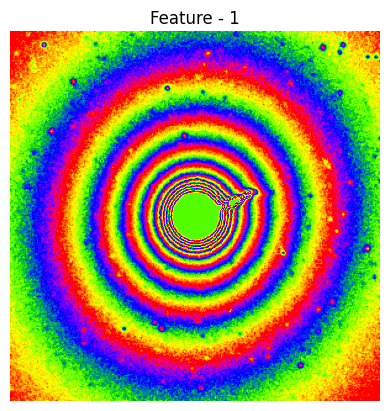

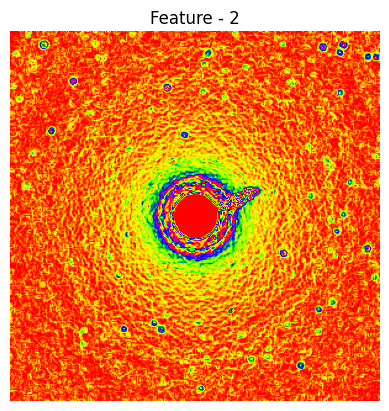

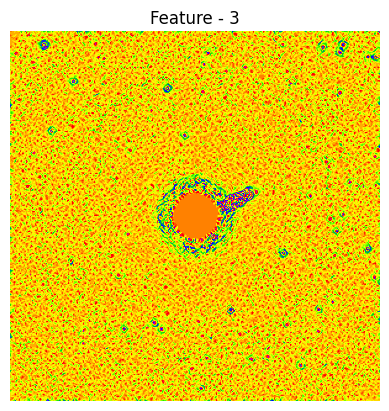

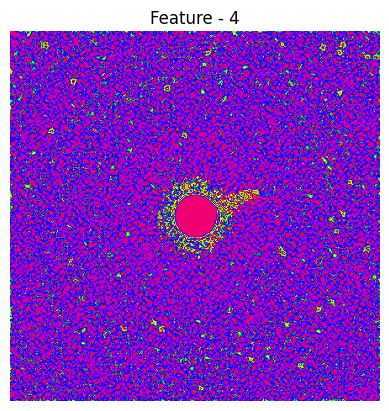

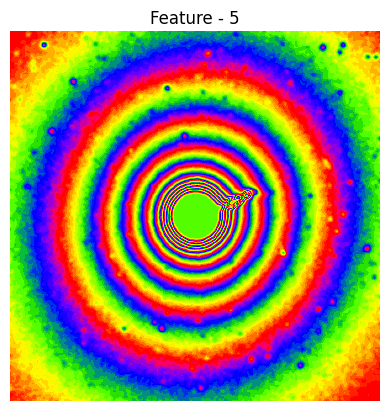

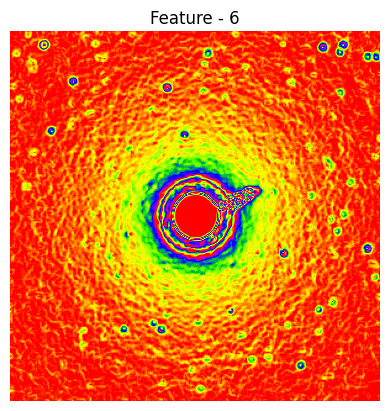

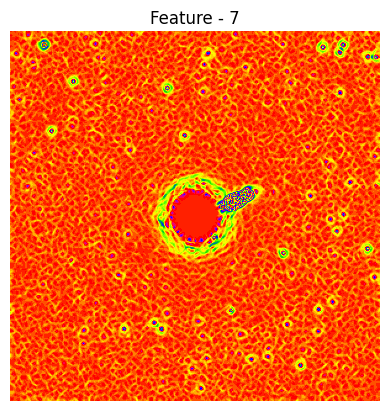

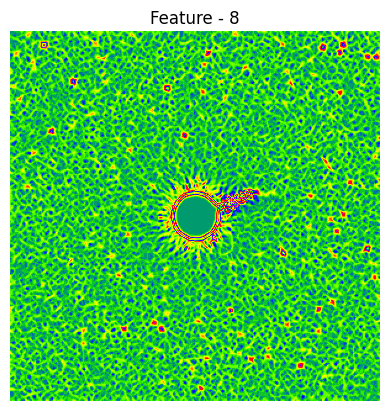

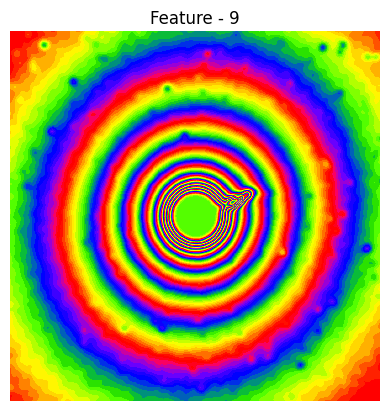

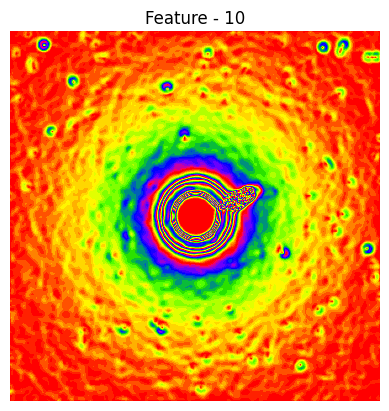

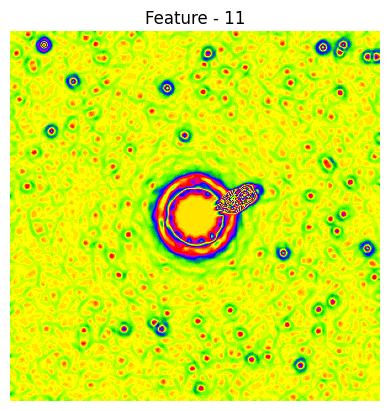

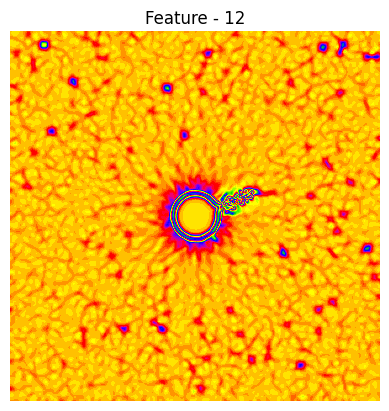

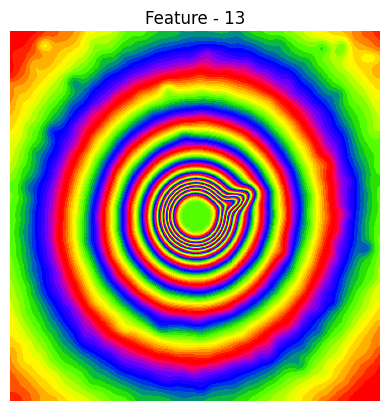

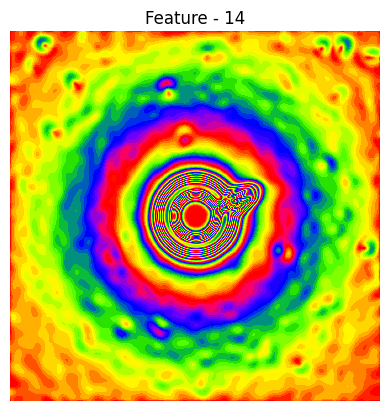

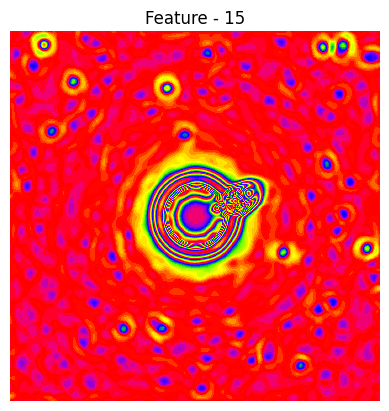

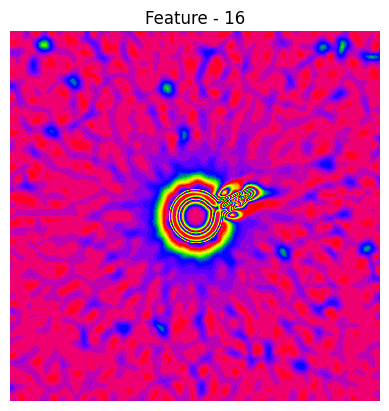

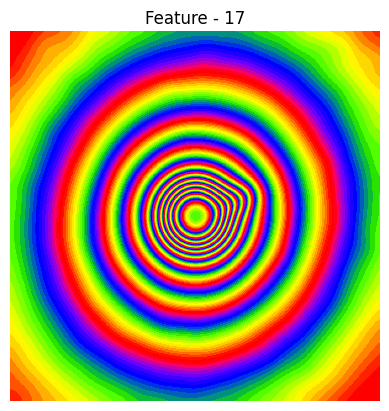

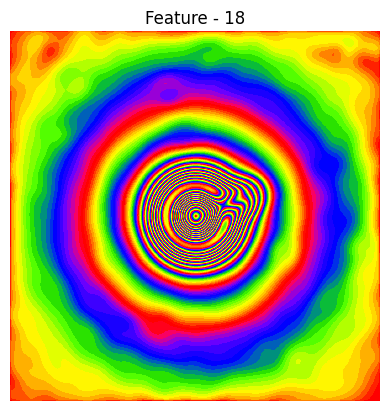

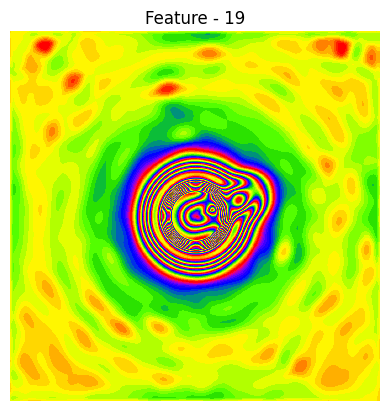

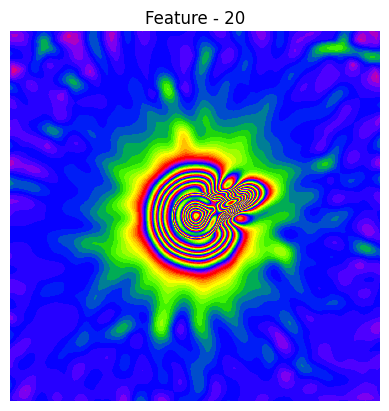

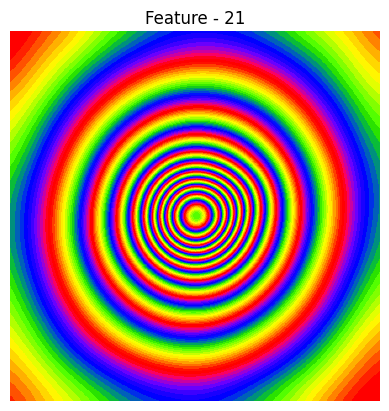

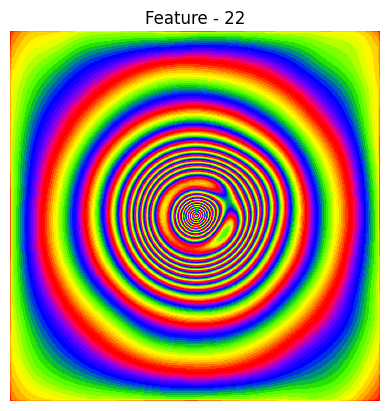

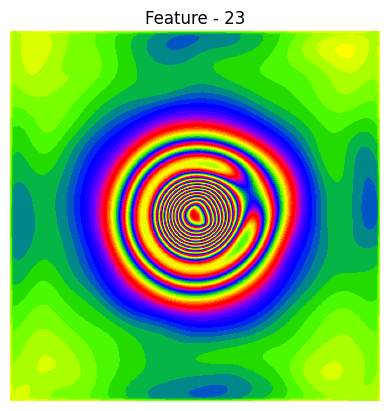

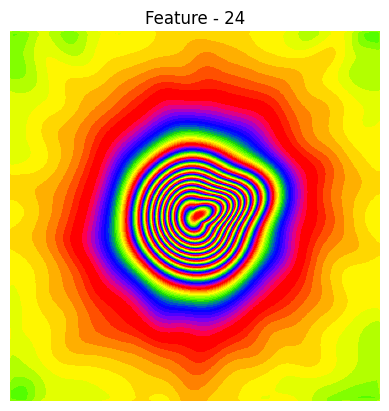

In [ ]:
# Write a for loop for each of these feature in Pixels list to visualize it using prism colormap
for index, feature_ in enumerate(Pixels):
  plt.imshow(feature_, cmap='prism', origin='lower')
  plt.axis('off')
  plt.title(f'Feature - {index+1}')
  plt.show()

---